# Рекомендательная система фильмов

**Цель работы:** разработать и проверить методы рекомендательной системы по фильмам.
**Данные:** MovieLens (GroupLens) - 100 836 оценок, 610 пользователей, 9 742 фильма. Постеры и описания - TMDB.

## 1. Импорт библиотек

In [1]:
import glob
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

## 2. Загрузка данных

Три таблицы:
- `movies.csv` - фильмы (id, название, год, жанры);
- `ratings (1).csv` - оценки пользователей (userId, movieId, rating, timestamp);
- `photo.csv` - из TMDB: ссылки на постеры, **описания (overview) на английском** (для рекомендаций), **описания на русском** (для карточки фильма) и русские названия.

In [2]:
movies = pd.read_csv("movies.csv")
photo = pd.read_csv("photo.csv")
ratings_file = sorted(glob.glob("rating*.csv"))[0]
print("Файл оценок:", ratings_file)
ratings = pd.read_csv(ratings_file)

print("movies :", movies.shape)
print("ratings:", ratings.shape)
print("photo  :", photo.shape)

Файл оценок: ratings (1).csv
movies : (9742, 6)
ratings: (100836, 4)
photo  : (9742, 7)


In [3]:
movies.head()

,movieId,imdbId,tmdbId,title,year,genres
0,1,tt0114709,862.000,Toy Story (1995),1995.000,Adventure|Animation|Children|Comedy|Fantasy
1,2,tt0113497,8844.000,Jumanji (1995),1995.000,Adventure|Children|Fantasy
2,3,tt0113228,15602.000,Grumpier Old Men (1995),1995.000,Comedy|Romance
3,4,tt0114885,31357.000,Waiting to Exhale (1995),1995.000,Comedy|Drama|Romance
4,5,tt0113041,11862.000,Father of the Bride Part II (1995),1995.000,Comedy


In [4]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.000,964982703
1,1,3,4.000,964981247
2,1,6,4.000,964982224
3,1,47,5.000,964983815
4,1,50,5.000,964982931


In [5]:
photo.head()

,movieId,imdbId,tmdbId,poster_url,overview,overview_ru,title_ru
0,1,tt0114709,862.000,https://image.tmdb.org/t/p/w342/uXDfjJbdP4ijW5hWSBrPrlKp...,"Led by Woody, Andy's toys live happily in his room until...","Каждый ребёнок верит, что когда он оставляет свои игрушк...",История игрушек
1,2,tt0113497,8844.000,https://image.tmdb.org/t/p/w342/bdHG5Mo83VPobeZZdlSz0Y7H...,When siblings Judy and Peter discover an enchanted board...,Случайно обнаружив настольную игру со странным названием...,Джуманджи
2,3,tt0113228,15602.000,https://image.tmdb.org/t/p/w342/1FSXpj5e8l4KH6nVFO5SPUer...,A family wedding reignites the ancient feud between next...,Лето пришло в городок Вадасу в Миннесоте и все растаяло....,Старые ворчуны разбушевались
3,4,tt0114885,31357.000,https://image.tmdb.org/t/p/w342/4wjGMwPsdlvi025ZqR4rXnFD...,"Cheated on, mistreated and stepped on, the women are hol...",В центре сюжета — судьбы четырех разных афроамериканских...,В ожидании выдоха
4,5,tt0113041,11862.000,https://image.tmdb.org/t/p/w342/rj4LBtwQ0uGrpBnCELr716Qo...,Just when George Banks has recovered from his daughter's...,"Он еще слишком молод, чтобы стать дедушкой, но уже доста...",Отец невесты 2


## 3. Объединение и обработка данных

In [6]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   movieId  9742 non-null   int64  
 1   imdbId   9742 non-null   object 
 2   tmdbId   9734 non-null   float64
 3   title    9742 non-null   object 
 4   year     9729 non-null   float64
 5   genres   9742 non-null   object 
dtypes: float64(2), int64(1), object(3)
memory usage: 456.8+ KB


In [7]:
# Пропуски и дубликаты
print("Пропусков в movies :", movies.isna().sum().to_dict())
print("Пропусков в ratings:", ratings.isna().sum().to_dict())
print("Дубликатов (userId, movieId):", ratings.duplicated(["userId", "movieId"]).sum())
print("Фильмов без жанров:", (movies.genres == "(no genres listed)").sum())

Пропусков в movies : {'movieId': 0, 'imdbId': 0, 'tmdbId': 8, 'title': 0, 'year': 13, 'genres': 0}
Пропусков в ratings: {'userId': 0, 'movieId': 0, 'rating': 0, 'timestamp': 0}
Дубликатов (userId, movieId): 0
Фильмов без жанров: 34


In [9]:
ratings = ratings.drop_duplicates(["userId", "movieId"])
movies["genres"] = movies["genres"].replace("(no genres listed)", "")
photo["poster_url"] = photo["poster_url"].fillna("")
for col in ("overview", "overview_ru", "title_ru"):
    if col not in photo:
        photo[col] = ""
    photo[col] = photo[col].fillna("")
print("Фильмов с описанием (EN):", (photo.overview != "").sum(), "из", len(photo))
print("Фильмов с описанием (RU):", (photo.overview_ru != "").sum(), "из", len(photo))
df = (ratings
      .merge(movies, on="movieId")
      .merge(photo[["movieId", "poster_url"]], on="movieId", how="left"))
df["poster_url"] = df["poster_url"].fillna("")
df = df.drop(columns=["timestamp"])
df.head()

Фильмов с описанием (EN): 9657 из 9742
Фильмов с описанием (RU): 8936 из 9742


,userId,movieId,rating,imdbId,tmdbId,title,year,genres,poster_url
0,1,1,4.000,tt0114709,862.000,Toy Story (1995),1995.000,Adventure|Animation|Children|Comedy|Fantasy,https://image.tmdb.org/t/p/w342/uXDfjJbdP4ijW5hWSBrPrlKp...
1,1,3,4.000,tt0113228,15602.000,Grumpier Old Men (1995),1995.000,Comedy|Romance,https://image.tmdb.org/t/p/w342/1FSXpj5e8l4KH6nVFO5SPUer...
2,1,6,4.000,tt0113277,949.000,Heat (1995),1995.000,Action|Crime|Thriller,https://image.tmdb.org/t/p/w342/umSVjVdbVwtx5ryCA2QXL44D...
3,1,47,5.000,tt0114369,807.000,Seven (a.k.a. Se7en) (1995),1995.000,Mystery|Thriller,https://image.tmdb.org/t/p/w342/191nKfP0ehp3uIvWqgPbFmI4...
4,1,50,5.000,tt0114814,629.000,"Usual Suspects, The (1995)",1995.000,Crime|Mystery|Thriller,https://image.tmdb.org/t/p/w342/99X2SgyFunJFXGAYnDv3sb9p...


### Знакомство с данными

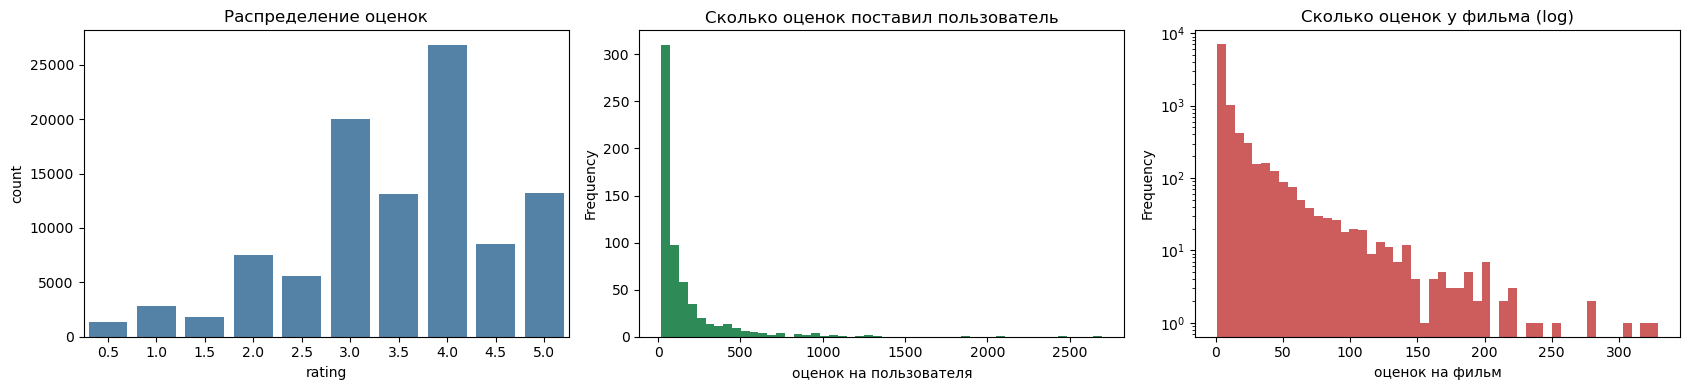

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

sns.countplot(x="rating", data=ratings, ax=ax[0], color="steelblue")
ax[0].set_title("Распределение оценок")

ratings.groupby("userId").size().plot.hist(bins=50, ax=ax[1], color="seagreen")
ax[1].set_title("Сколько оценок поставил пользователь")
ax[1].set_xlabel("оценок на пользователя")

ratings.groupby("movieId").size().plot.hist(bins=50, ax=ax[2], color="indianred", log=True)
ax[2].set_title("Сколько оценок у фильма (log)")
ax[2].set_xlabel("оценок на фильм")
plt.tight_layout()
plt.show()

In [11]:
sparsity = 1 - len(ratings) / (ratings.userId.nunique() * ratings.movieId.nunique())
print(f"Пользователей: {ratings.userId.nunique()},  фильмов с оценками: {ratings.movieId.nunique()}")
print(f"Разреженность матрицы «пользователь × фильм»: {sparsity:.2%}")

Пользователей: 610,  фильмов с оценками: 9724
Разреженность матрицы «пользователь × фильм»: 98.30%


Матрица оценок разрежена более чем на 98 %: каждый пользователь видел лишь малую часть фильмов.
Поэтому дальше используем разреженные матрицы (`csr_matrix`).

## 4. Рекомендации на основе популярности (взвешенный рейтинг)

Простой средний рейтинг несправедлив: фильм с одной оценкой «5.0» обгонит фильм с 1000 оценок «4.5».
Поэтому применяем формулу IMDb (Bayesian average):

$$WR = \frac{v}{v+m}\cdot R + \frac{m}{v+m}\cdot C$$

- v - число оценок фильма; R - средний рейтинг фильма;
- m - «порог доверия» (90-й процентиль числа оценок);
- C - средний рейтинг по всем фильмам.

In [12]:
movie_stats = (df.groupby("movieId")
                 .agg(avg_rating=("rating", "mean"), count_rating=("rating", "count"))
                 .reset_index())

v = movie_stats["count_rating"]
R = movie_stats["avg_rating"]
m = v.quantile(0.90)
C = R.mean()
movie_stats["w_score"] = (v * R + m * C) / (v + m)
print(f"m (порог доверия) = {m:.0f},  C (средний рейтинг) = {C:.3f}")


catalog = (movies.merge(photo[["movieId", "poster_url", "overview", "overview_ru", "title_ru"]], on="movieId", how="left")
                 .merge(movie_stats, on="movieId", how="left"))
catalog["poster_url"] = catalog["poster_url"].fillna("")
for col in ("overview", "overview_ru", "title_ru"):
    catalog[col] = catalog[col].fillna("")
catalog["count_rating"] = catalog["count_rating"].fillna(0).astype(int)
catalog = catalog.set_index("movieId", drop=False)

movie_stats.describe()

m (порог доверия) = 27,  C (средний рейтинг) = 3.262


,movieId,avg_rating,count_rating,w_score
count,9724.000,9724.000,9724.000,9724.000
mean,42245.024,3.262,10.370,3.283
std,52191.137,0.870,22.401,0.147
min,1.000,0.500,1.000,2.543
25%,3245.500,2.800,1.000,3.217
50%,7300.000,3.417,3.000,3.271
75%,76739.250,3.912,9.000,3.325
max,193609.000,5.000,329.000,4.337


In [13]:
def popular_movies(n=10, genre=None, min_votes=0):
    d = catalog[catalog.count_rating > min_votes]
    if genre:
        d = d[d.genres.str.split("|").apply(lambda g: genre in g)]
    cols = ["movieId", "title", "genres", "avg_rating", "count_rating", "w_score", "poster_url"]
    return d.sort_values("w_score", ascending=False).head(n)[cols].reset_index(drop=True)

top10 = popular_movies(10)
top10

,movieId,title,genres,avg_rating,count_rating,w_score,poster_url
0,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.429,317,4.337,https://image.tmdb.org/t/p/w342/9cqNxx0GxF0bflZmeSMuL5tn...
1,858,"Godfather, The (1972)",Crime|Drama,4.289,192,4.162,https://image.tmdb.org/t/p/w342/3bhkrj58Vtu7enYsRolD1fZd...
2,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.273,218,4.162,https://image.tmdb.org/t/p/w342/jSziioSwPVrOy9Yow3XhWIBD...
3,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,4.137,https://image.tmdb.org/t/p/w342/fai0rspsNeJCS69wHNjOdWxc...
4,50,"Usual Suspects, The (1995)",Crime|Mystery|Thriller,4.238,204,4.124,https://image.tmdb.org/t/p/w342/99X2SgyFunJFXGAYnDv3sb9p...
5,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197,307,4.122,https://image.tmdb.org/t/p/w342/vQWk5YBFWF4bZaofAbv0tShw...
6,527,Schindler's List (1993),Drama|War,4.225,220,4.120,https://image.tmdb.org/t/p/w342/sF1U4EUQS8YHUYjNl3pMGNIQ...
7,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.192,278,4.110,https://image.tmdb.org/t/p/w342/dXNAPwY7VrqMAo51EKhhCJfa...
8,1196,Star Wars: Episode V - The Empire Strikes Back (1980),Action|Adventure|Sci-Fi,4.216,211,4.108,https://image.tmdb.org/t/p/w342/nNAeTmF4CtdSgMDplXTDPOpY...
9,356,Forrest Gump (1994),Comedy|Drama|Romance|War,4.164,329,4.096,https://image.tmdb.org/t/p/w342/saHP97rTPS5eLmrLQEcANmKr...


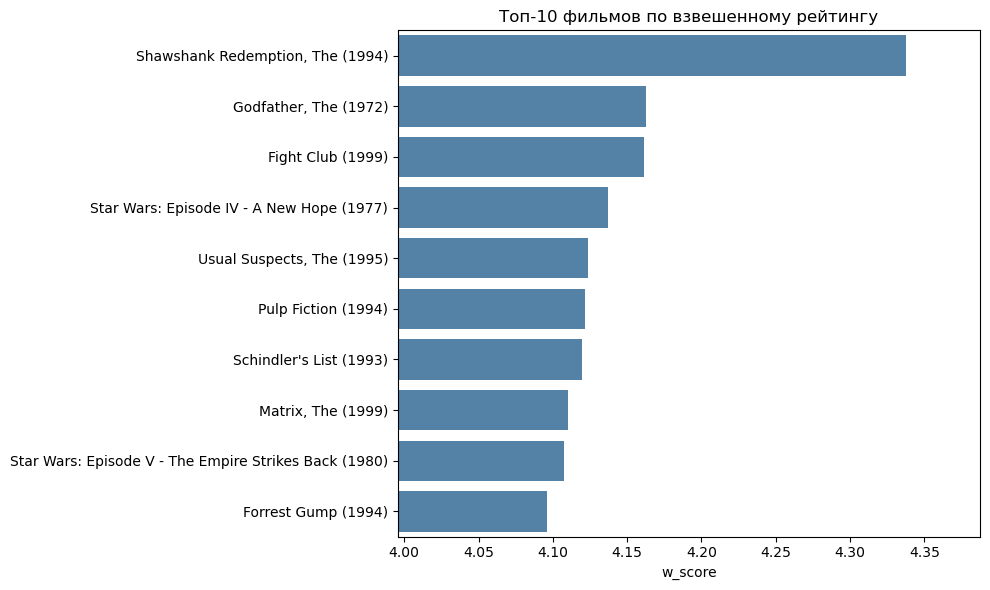

In [14]:
plt.figure(figsize=(10, 6))
sns.barplot(x="w_score", y="title", data=top10, color="steelblue")
plt.xlim(top10.w_score.min() - 0.1, top10.w_score.max() + 0.05)
plt.title("Топ-10 фильмов по взвешенному рейтингу")
plt.xlabel("w_score")
plt.ylabel("")
plt.tight_layout()
plt.show()

Топ по жанру:

In [15]:
popular_movies(10, genre="Comedy")

,movieId,title,genres,avg_rating,count_rating,w_score,poster_url
0,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197,307,4.122,https://image.tmdb.org/t/p/w342/vQWk5YBFWF4bZaofAbv0tShw...
1,356,Forrest Gump (1994),Comedy|Drama|Romance|War,4.164,329,4.096,https://image.tmdb.org/t/p/w342/saHP97rTPS5eLmrLQEcANmKr...
2,1197,"Princess Bride, The (1987)",Action|Adventure|Comedy|Fantasy|Romance,4.232,142,4.077,https://image.tmdb.org/t/p/w342/2FC9L9MrjBoGHYjYZjdWQdop...
3,750,Dr. Strangelove or: How I Learned to Stop Worrying and L...,Comedy|War,4.268,97,4.049,https://image.tmdb.org/t/p/w342/gHm96BRW4GoI339rF1vYoYTB...
4,4973,"Amelie (Fabuleux destin d'Amélie Poulain, Le) (2001)",Comedy|Romance,4.183,120,4.014,https://image.tmdb.org/t/p/w342/nSxDa3M9aMvGVLoItzWTepQ5...
5,1136,Monty Python and the Holy Grail (1975),Adventure|Comedy|Fantasy,4.162,136,4.013,https://image.tmdb.org/t/p/w342/7nTkHjETdGMYK1phHwDbPsrz...
6,608,Fargo (1996),Comedy|Crime|Drama|Thriller,4.116,181,4.005,https://image.tmdb.org/t/p/w342/rt7cpEr1uP6RTZykBFhBTcRa...
7,4011,Snatch (2000),Comedy|Crime|Thriller,4.156,93,3.955,https://image.tmdb.org/t/p/w342/kJZoAHq1SLDdWjeNGtlHAnGp...
8,2324,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,4.148,88,3.940,https://image.tmdb.org/t/p/w342/74hLDKjD5aGYOotO6esUVaeI...
9,1270,Back to the Future (1985),Adventure|Comedy|Sci-Fi,4.038,171,3.932,https://image.tmdb.org/t/p/w342/vN5B5WgYscRGcQpVhHl6p9DD...


In [16]:
popular_movies(10, genre="Sci-Fi")

,movieId,title,genres,avg_rating,count_rating,w_score,poster_url
0,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,4.137,https://image.tmdb.org/t/p/w342/fai0rspsNeJCS69wHNjOdWxc...
1,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,4.192,278,4.110,https://image.tmdb.org/t/p/w342/dXNAPwY7VrqMAo51EKhhCJfa...
2,1196,Star Wars: Episode V - The Empire Strikes Back (1980),Action|Adventure|Sci-Fi,4.216,211,4.108,https://image.tmdb.org/t/p/w342/nNAeTmF4CtdSgMDplXTDPOpY...
3,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,4.138,196,4.032,https://image.tmdb.org/t/p/w342/jQYlydvHm3kUix1f8prMucrp...
4,7361,Eternal Sunshine of the Spotless Mind (2004),Drama|Romance|Sci-Fi,4.160,131,4.007,https://image.tmdb.org/t/p/w342/5MwkWH9tYHv3mV9OdYTMR5qr...
5,541,Blade Runner (1982),Action|Sci-Fi|Thriller,4.101,124,3.951,https://image.tmdb.org/t/p/w342/63N9uy8nd9j7Eog2axPQ8lbr...
6,79132,Inception (2010),Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,4.066,143,3.939,https://image.tmdb.org/t/p/w342/xlaY2zyzMfkhk0HSC5VUwzoZ...
7,1270,Back to the Future (1985),Adventure|Comedy|Sci-Fi,4.038,171,3.932,https://image.tmdb.org/t/p/w342/vN5B5WgYscRGcQpVhHl6p9DD...
8,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi,3.971,224,3.895,https://image.tmdb.org/t/p/w342/jFTVD4XoWQTcg7wdyJKa8PEd...
9,60069,WALL·E (2008),Adventure|Animation|Children|Romance|Sci-Fi,4.058,104,3.894,https://image.tmdb.org/t/p/w342/hbhFnRzzg6ZDmm8YAmxBnQpQ...


**Минус подхода:** всем пользователям показывается одно и то же. Для персонализации нужна коллаборативная фильтрация.

## 5. Матрица «пользователь x фильм»

Строки - пользователи, столбцы - фильмы.

In [17]:
user_ids = np.sort(ratings.userId.unique())
movie_ids = np.sort(ratings.movieId.unique())
uidx = {u: i for i, u in enumerate(user_ids)}
midx = {mv: i for i, mv in enumerate(movie_ids)}

rows = ratings.userId.map(uidx).values
cols = ratings.movieId.map(midx).values
UI = csr_matrix((ratings.rating.values, (rows, cols)), shape=(len(user_ids), len(movie_ids)))
print("Матрица пользователь × фильм:", UI.shape, " ненулевых:", UI.nnz)

Матрица пользователь × фильм: (610, 9724)  ненулевых: 100836


### Вспомогательные функции: поиск фильма по названию и красивый вывод

In [18]:
def find_movie(query):

    mask = catalog.title.str.contains(re.escape(query), case=False, na=False)
    found = catalog[mask].sort_values("count_rating", ascending=False)
    if found.empty:
        raise ValueError(f"Фильм «{query}» не найден")
    return int(found.iloc[0].movieId)


def show(movie_id_list, extra=None):

    out = catalog.loc[movie_id_list, ["movieId", "title", "genres", "avg_rating", "count_rating", "w_score", "poster_url"]].copy()
    if extra is not None:
        for k, val in extra.items():
            out[k] = val
    return out.reset_index(drop=True)


def movie_card(query):
    
    mid = query if isinstance(query, (int, np.integer)) else find_movie(query)
    m = catalog.loc[mid]
    print(m.title + (f"  /  {m.title_ru}" if m.title_ru else ""))
    print(f"Год: {int(m.year) if pd.notna(m.year) else '—'} | Жанры: {m.genres.replace('|', ', ') or '—'}")
    print(f"Рейтинг: {m.avg_rating:.2f} ({m.count_rating} оценок) | Взвешенный: {m.w_score:.2f}")
    print("Постер:", m.poster_url or "нет")
    if m.overview_ru:
        print("\nОписание:", m.overview_ru)
    elif m.overview:
        print("\nОписание (русского нет, показано английское):", m.overview)

In [19]:
movie_card("Matrix, The")

Matrix, The (1999)  /  Матрица
Год: 1999 | Жанры: Action, Sci-Fi, Thriller
Рейтинг: 4.19 (278 оценок) | Взвешенный: 4.11
Постер: https://image.tmdb.org/t/p/w342/dXNAPwY7VrqMAo51EKhhCJfaGb5.jpg

Описание: Жизнь Томаса Андерсона разделена на две части: днём он — самый обычный офисный работник, получающий нагоняи от начальства, а ночью превращается в хакера по имени Нео, и нет места в сети, куда он бы не смог проникнуть. Но однажды всё меняется. Томас узнаёт ужасающую правду о реальности.


## 6. Коллаборативная фильтрация по ПОЛЬЗОВАТЕЛЯМ (user-based)

**Идея:** найти пользователей с похожим вкусом и порекомендовать то, что понравилось им, но чего целевой пользователь ещё не видел.

In [20]:
knn_user = NearestNeighbors(metric="cosine", algorithm="brute")
knn_user.fit(UI)


def _scores_from_vector(vec, k=30, shrink=1.0):
    dist, ind = knn_user.kneighbors(vec, n_neighbors=k + 1)
    dist, ind = dist[0], ind[0]
    sim = 1 - dist
    keep = (sim < 0.9999) & (sim > 0)
    sim, ind = sim[keep], ind[keep]
    neigh = UI[ind]
    num = neigh.T.dot(sim)                           # сумма sim * rating
    den = (neigh > 0).T.astype(float).dot(sim)       # сумма sim по тем, кто оценил
    return num / (den + shrink), den


def recommend_for_ratings(user_ratings, n=10, k=30, min_neighbors_weight=0.5, genres=None):
    vec = np.zeros(len(movie_ids))
    for mv, r in user_ratings.items():
        if mv in midx:
            vec[midx[mv]] = r
    scores, den = _scores_from_vector(csr_matrix(vec), k=k)
    scores = np.asarray(scores).ravel()
    den = np.asarray(den).ravel()
    scores[vec > 0] = -1                          # уже смотрел
    scores[den < min_neighbors_weight] = -1       # слишком мало «голосов» соседей
    order = np.argsort(-scores)
    order = [i for i in order if scores[i] > 0]
    if genres:
        order = [i for i in order if genres in catalog.loc[movie_ids[i], "genres"]]
    order = order[:n]
    ids = [int(movie_ids[i]) for i in order]
    return show(ids, {"score": [scores[i] for i in order]})


def recommend_user_cf(user_id, n=10, k=30):
    i = uidx[user_id]
    seen = {int(movie_ids[j]): UI[i, j] for j in UI[i].indices}
    return recommend_for_ratings(seen, n=n, k=k)

In [21]:
user = 1
print("Любимые фильмы пользователя", user)
fav = ratings[ratings.userId == user].sort_values("rating", ascending=False).head(10)
show(fav.movieId.tolist(), {"user_rating": fav.rating.tolist()})[["title", "genres", "user_rating"]]

Любимые фильмы пользователя 1


,title,genres,user_rating
0,M*A*S*H (a.k.a. MASH) (1970),Comedy|Drama|War,5.000
1,Excalibur (1981),Adventure|Fantasy,5.000
2,Indiana Jones and the Last Crusade (1989),Action|Adventure,5.000
3,Pink Floyd: The Wall (1982),Drama|Musical,5.000
4,From Russia with Love (1963),Action|Adventure|Thriller,5.000
5,Goldfinger (1964),Action|Adventure|Thriller,5.000
6,"Dirty Dozen, The (1967)",Action|Drama|War,5.000
7,Gulliver's Travels (1939),Adventure|Animation|Children,5.000
8,American Beauty (1999),Drama|Romance,5.000
9,"South Park: Bigger, Longer and Uncut (1999)",Animation|Comedy|Musical,5.000


In [22]:
print("Рекомендации user-based CF для пользователя", user)
recommend_user_cf(user)

Рекомендации user-based CF для пользователя 1


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,score
0,858,"Godfather, The (1972)",Crime|Drama,4.289,192,4.162,https://image.tmdb.org/t/p/w342/3bhkrj58Vtu7enYsRolD1fZd...,4.092
1,1221,"Godfather: Part II, The (1974)",Crime|Drama,4.260,129,4.087,https://image.tmdb.org/t/p/w342/8a1lJs7mFyGhGhZZDT1azJUo...,3.861
2,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.429,317,4.337,https://image.tmdb.org/t/p/w342/9cqNxx0GxF0bflZmeSMuL5tn...,3.799
3,1387,Jaws (1975),Action|Horror,4.005,91,3.835,https://image.tmdb.org/t/p/w342/lxM6kqilAdpdhqUl2biYp5fr...,3.794
4,2762,"Sixth Sense, The (1999)",Drama|Horror|Mystery,3.894,179,3.811,https://image.tmdb.org/t/p/w342/vOyfUXNFSnaTk7Vk5AjpsKTU...,3.727
5,4993,"Lord of the Rings: The Fellowship of the Ring, The (2001)",Adventure|Fantasy,4.106,198,4.005,https://image.tmdb.org/t/p/w342/6oom5QYQ2yQTMJIbnvbkBL9c...,3.709
6,1200,Aliens (1986),Action|Adventure|Horror|Sci-Fi,3.964,126,3.840,https://image.tmdb.org/t/p/w342/r1x5JGpyqZU8PYhbs4UcrO1X...,3.708
7,541,Blade Runner (1982),Action|Sci-Fi|Thriller,4.101,124,3.951,https://image.tmdb.org/t/p/w342/63N9uy8nd9j7Eog2axPQ8lbr...,3.686
8,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi,3.971,224,3.895,https://image.tmdb.org/t/p/w342/jFTVD4XoWQTcg7wdyJKa8PEd...,3.678
9,1653,Gattaca (1997),Drama|Sci-Fi|Thriller,3.953,86,3.788,https://image.tmdb.org/t/p/w342/eSKr5Fl1MEC7zpAXaLWBWSBj...,3.665


In [23]:
user = 414
print("Любимые фильмы пользователя", user)
fav = ratings[ratings.userId == user].sort_values("rating", ascending=False).head(10)
display(show(fav.movieId.tolist(), {"user_rating": fav.rating.tolist()})[["title", "genres", "user_rating"]])
print("Рекомендации:")
recommend_user_cf(user)

Любимые фильмы пользователя 414


,title,genres,user_rating
0,"Great Escape, The (1963)",Action|Adventure|Drama|War,5.000
1,Dr. Strangelove or: How I Learned to Stop Worrying and L...,Comedy|War,5.000
2,"Princess and the Warrior, The (Krieger und die Kaiserin,...",Drama|Romance,5.000
3,It's a Wonderful Life (1946),Children|Drama|Fantasy|Romance,5.000
4,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi,5.000
5,Citizen Kane (1941),Drama|Mystery,5.000
6,Roman Holiday (1953),Comedy|Drama|Romance,5.000
7,Peter Pan (1953),Animation|Children|Fantasy|Musical,5.000
8,Casablanca (1942),Drama|Romance,5.000
9,Some Like It Hot (1959),Comedy|Crime,5.000


Рекомендации:


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,score
0,1203,12 Angry Men (1957),Drama,4.149,57,3.864,https://image.tmdb.org/t/p/w342/zhG3vKWyDRaZYoaww1UVAi29...,3.711
1,1258,"Shining, The (1980)",Horror,4.083,109,3.920,https://image.tmdb.org/t/p/w342/uAR0AWqhQL1hQa69UDEbb2rE...,3.645
2,1219,Psycho (1960),Crime|Horror,4.036,83,3.846,https://image.tmdb.org/t/p/w342/yz4QVqPx3h1hD1DfqqQkCq3r...,3.623
3,2288,"Thing, The (1982)",Action|Horror|Sci-Fi|Thriller,3.933,45,3.682,https://image.tmdb.org/t/p/w342/tzGY49kseSE9QAKk47uuDGwn...,3.513
4,7022,Battle Royale (Batoru rowaiaru) (2000),Action|Drama|Horror|Thriller,3.933,30,3.616,https://image.tmdb.org/t/p/w342/aLGKAQKgzWpJ6egyWzzC11jX...,3.508
5,8368,Harry Potter and the Prisoner of Azkaban (2004),Adventure|Fantasy|IMAX,3.914,93,3.767,https://image.tmdb.org/t/p/w342/aWxwnYoe8p2d2fcxOqtvAtJ7...,3.480
6,7387,Dawn of the Dead (1978),Action|Drama|Horror,3.975,20,3.566,https://image.tmdb.org/t/p/w342/70MY8H0bLMvXf8ED2SgVMPhD...,3.430
7,2324,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,4.148,88,3.940,https://image.tmdb.org/t/p/w342/74hLDKjD5aGYOotO6esUVaeI...,3.415
8,3681,For a Few Dollars More (Per qualche dollaro in più) (1965),Action|Drama|Thriller|Western,4.152,33,3.751,https://image.tmdb.org/t/p/w342/ooqASvA7qxlTVKL3KwOzBwy5...,3.314
9,70,From Dusk Till Dawn (1996),Action|Comedy|Horror|Thriller,3.509,55,3.428,https://image.tmdb.org/t/p/w342/sV3kIAmvJ9tPz4Lq5fuf9LLM...,3.273


Рекомендации у двух пользователей отличаются - система персонализирована.

## 7. Коллаборативная фильтрация по ФИЛЬМАМ (item-based)

Идея: если пользователю понравился фильм определенный фильм, порекомендуем фильмы, которые похожи с этим фильмом по паттерну оценок.

In [24]:
MIN_ITEM_RATINGS = 10
cnt = np.asarray((UI > 0).sum(axis=0)).ravel()
item_cols = np.where(cnt >= MIN_ITEM_RATINGS)[0]
item_movie_ids = movie_ids[item_cols]
iidx = {int(mv): i for i, mv in enumerate(item_movie_ids)}

IU = UI[:, item_cols].T.tocsr()                      # фильмы × пользователи
print(f"Фильмов в item-модели (≥{MIN_ITEM_RATINGS} оценок): {IU.shape[0]} из {len(movie_ids)}")

knn_item = NearestNeighbors(metric="cosine", algorithm="brute")
knn_item.fit(IU)


def similar_movies_cf(title_or_id, n=10):
    mid = title_or_id if isinstance(title_or_id, (int, np.integer)) else find_movie(title_or_id)
    if mid not in iidx:
        raise ValueError("У фильма слишком мало оценок для item-based модели")
    dist, ind = knn_item.kneighbors(IU[iidx[mid]], n_neighbors=n + 1)
    ids = [int(item_movie_ids[j]) for j in ind[0][1:]]
    print("Фильм:", catalog.loc[mid, "title"])
    return show(ids, {"similarity": 1 - dist[0][1:]})

Фильмов в item-модели (≥10 оценок): 2269 из 9724


In [25]:
similar_movies_cf("Toy Story (1995)")

Фильм: Toy Story (1995)


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,similarity
0,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.861,97,3.731,https://image.tmdb.org/t/p/w342/4rbcp3ng8n1MKHjpeqW0L7Fn...,0.573
1,480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,3.750,238,3.700,https://image.tmdb.org/t/p/w342/d9mtMGQDLANKieb9PbD3yK7x...,0.566
2,780,Independence Day (a.k.a. ID4) (1996),Action|Adventure|Sci-Fi|Thriller,3.446,202,3.424,https://image.tmdb.org/t/p/w342/p0BPQGSPoSa8Ml0DAf2mB2kC...,0.564
3,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,4.137,https://image.tmdb.org/t/p/w342/fai0rspsNeJCS69wHNjOdWxc...,0.557
4,356,Forrest Gump (1994),Comedy|Drama|Romance|War,4.164,329,4.096,https://image.tmdb.org/t/p/w342/saHP97rTPS5eLmrLQEcANmKr...,0.547
5,364,"Lion King, The (1994)",Adventure|Animation|Children|Drama|Musical|IMAX,3.942,172,3.850,https://image.tmdb.org/t/p/w342/sKCr78MXSLixwmZ8DyJLrpMs...,0.541
6,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,4.138,196,4.032,https://image.tmdb.org/t/p/w342/jQYlydvHm3kUix1f8prMucrp...,0.541
7,648,Mission: Impossible (1996),Action|Adventure|Mystery|Thriller,3.537,162,3.498,https://image.tmdb.org/t/p/w342/l5uxY5m5OInWpcExIpKG6AR3...,0.539
8,1265,Groundhog Day (1993),Comedy|Fantasy|Romance,3.944,143,3.836,https://image.tmdb.org/t/p/w342/gCgt1WARPZaXnq523ySQEUKi...,0.534
9,1270,Back to the Future (1985),Adventure|Comedy|Sci-Fi,4.038,171,3.932,https://image.tmdb.org/t/p/w342/vN5B5WgYscRGcQpVhHl6p9DD...,0.530


In [26]:
similar_movies_cf("Matrix, The")

Фильм: Matrix, The (1999)


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,similarity
0,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.273,218,4.162,https://image.tmdb.org/t/p/w342/jSziioSwPVrOy9Yow3XhWIBD...,0.714
1,1196,Star Wars: Episode V - The Empire Strikes Back (1980),Action|Adventure|Sci-Fi,4.216,211,4.108,https://image.tmdb.org/t/p/w342/nNAeTmF4CtdSgMDplXTDPOpY...,0.701
2,2028,Saving Private Ryan (1998),Action|Drama|War,4.146,188,4.035,https://image.tmdb.org/t/p/w342/uqx37cS8cpHg8U35f9U5IBlr...,0.680
3,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,4.137,https://image.tmdb.org/t/p/w342/fai0rspsNeJCS69wHNjOdWxc...,0.663
4,1210,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,4.138,196,4.032,https://image.tmdb.org/t/p/w342/jQYlydvHm3kUix1f8prMucrp...,0.661
5,4993,"Lord of the Rings: The Fellowship of the Ring, The (2001)",Adventure|Fantasy,4.106,198,4.005,https://image.tmdb.org/t/p/w342/6oom5QYQ2yQTMJIbnvbkBL9c...,0.654
6,2762,"Sixth Sense, The (1999)",Drama|Horror|Mystery,3.894,179,3.811,https://image.tmdb.org/t/p/w342/vOyfUXNFSnaTk7Vk5AjpsKTU...,0.651
7,7153,"Lord of the Rings: The Return of the King, The (2003)",Action|Adventure|Drama|Fantasy,4.119,185,4.010,https://image.tmdb.org/t/p/w342/rCzpDGLbOoPwLjy3OAm5NUPO...,0.640
8,1198,Raiders of the Lost Ark (Indiana Jones and the Raiders o...,Action|Adventure,4.207,200,4.095,https://image.tmdb.org/t/p/w342/ceG9VzoRAVGwivFU403Wc3AH...,0.631
9,3578,Gladiator (2000),Action|Adventure|Drama,3.938,170,3.846,https://image.tmdb.org/t/p/w342/aDb548BOkFfI4nFm0kx8A3Ez...,0.626


In [27]:
similar_movies_cf("Godfather, The (1972)")

Фильм: Godfather, The (1972)


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,similarity
0,1221,"Godfather: Part II, The (1974)",Crime|Drama,4.260,129,4.087,https://image.tmdb.org/t/p/w342/8a1lJs7mFyGhGhZZDT1azJUo...,0.822
1,1213,Goodfellas (1990),Crime|Drama,4.250,126,4.076,https://image.tmdb.org/t/p/w342/9OkCLM73MIU2CrKZbqiT8Ln1...,0.665
2,1193,One Flew Over the Cuckoo's Nest (1975),Drama,4.203,133,4.044,https://image.tmdb.org/t/p/w342/kjWsMh72V6d8KRLV4EOoSJLT...,0.621
3,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,4.231,251,4.137,https://image.tmdb.org/t/p/w342/fai0rspsNeJCS69wHNjOdWxc...,0.595
4,608,Fargo (1996),Comedy|Crime|Drama|Thriller,4.116,181,4.005,https://image.tmdb.org/t/p/w342/rt7cpEr1uP6RTZykBFhBTcRa...,0.589
5,1196,Star Wars: Episode V - The Empire Strikes Back (1980),Action|Adventure|Sci-Fi,4.216,211,4.108,https://image.tmdb.org/t/p/w342/nNAeTmF4CtdSgMDplXTDPOpY...,0.586
6,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.273,218,4.162,https://image.tmdb.org/t/p/w342/jSziioSwPVrOy9Yow3XhWIBD...,0.581
7,1089,Reservoir Dogs (1992),Crime|Mystery|Thriller,4.202,131,4.042,https://image.tmdb.org/t/p/w342/xi8Iu6qyTfyZVDVy60raIOYJ...,0.579
8,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,4.197,307,4.122,https://image.tmdb.org/t/p/w342/vQWk5YBFWF4bZaofAbv0tShw...,0.575
9,2858,American Beauty (1999),Drama|Romance,4.056,204,3.964,https://image.tmdb.org/t/p/w342/wby9315QzVKdW9BonAefg8jG...,0.575


## 8. Рекомендации по КОНТЕНТУ (content-based)

In [29]:
def decade_token(year):
    return f"decade{int(year) // 10 * 10}" if pd.notna(year) else ""

genres_txt = catalog.genres.str.replace("-", "", regex=False).str.replace("|", " ", regex=False).str.lower()
content_text = catalog.overview + " " + (genres_txt + " ") * 3 + catalog.year.apply(decade_token)

tfidf = TfidfVectorizer(token_pattern=r"[A-Za-z0-9]{2,}", stop_words="english",
                        ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_content = tfidf.fit_transform(content_text)
print("Матрица признаков:", X_content.shape)
print("Примеры признаков:", list(tfidf.get_feature_names_out()[:: max(1, X_content.shape[1] // 12)]))

knn_content = NearestNeighbors(metric="cosine", algorithm="brute").fit(X_content)
cat_pos = {int(mid): i for i, mid in enumerate(catalog.index)}

Матрица признаков: (9742, 32021)
Примеры признаков: ['00', 'begins terrorizing', 'comics', 'doctor love', 'finding way', 'hide truth', 'latest assignment', 'mission locate', 'phone rings', 'rivalries', 'stalking', 'trying save', 'zoo']


In [30]:
def similar_movies_content(title_or_id, n=10, pool=200, min_votes=20):
    mid = title_or_id if isinstance(title_or_id, (int, np.integer)) else find_movie(title_or_id)
    dist, ind = knn_content.kneighbors(X_content[cat_pos[mid]], n_neighbors=pool)
    cand = catalog.iloc[ind[0]].copy()
    cand["similarity"] = (1 - dist[0]).round(3)
    cand = cand[(cand.movieId != mid) & (cand.count_rating >= min_votes)]
    cand = cand.sort_values(["similarity", "w_score"], ascending=False).head(n)
    print("Фильм:", catalog.loc[mid, "title"], "|", catalog.loc[mid, "genres"])
    return cand[["movieId", "title", "genres", "avg_rating", "count_rating", "w_score", "poster_url", "similarity"]].reset_index(drop=True)

In [31]:
similar_movies_content("Toy Story (1995)")

Фильм: Toy Story (1995) | Adventure|Animation|Children|Comedy|Fantasy


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,similarity
0,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,3.861,97,3.731,https://image.tmdb.org/t/p/w342/4rbcp3ng8n1MKHjpeqW0L7Fn...,0.563
1,78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,4.109,55,3.830,https://image.tmdb.org/t/p/w342/AbbXspMOwdvwWZgVN0nabZq0...,0.457
2,4016,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,3.716,37,3.525,https://image.tmdb.org/t/p/w342/wwbgkXQBEKtnyIJapk6gUgWk...,0.321
3,2294,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,3.244,45,3.251,https://image.tmdb.org/t/p/w342/lWPjxbUMpAHFkJpZHHNWhQaR...,0.302
4,108932,The Lego Movie (2014),Action|Adventure|Animation|Children|Comedy|Fantasy,3.871,31,3.588,https://image.tmdb.org/t/p/w342/lbctonEnewCYZ4FYoTZhs8ci...,0.270
5,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,3.871,132,3.768,https://image.tmdb.org/t/p/w342/wFSpyMsp7H0ttERbxY7Trlv8...,0.263
6,673,Space Jam (1996),Adventure|Animation|Children|Comedy|Fantasy|Sci-Fi,2.708,53,2.895,https://image.tmdb.org/t/p/w342/4RN5El3Pj2W4gpwgiAGLVfSJ...,0.259
7,53121,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,3.024,21,3.158,https://image.tmdb.org/t/p/w342/n4SexGGQzI26E269tfpa80MZ...,0.254
8,27706,Lemony Snicket's A Series of Unfortunate Events (2004),Adventure|Children|Comedy|Fantasy,3.160,25,3.213,https://image.tmdb.org/t/p/w342/r7S57FpBsCljWc9fBUo2Iy5X...,0.231
9,4306,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Romance,3.868,170,3.785,https://image.tmdb.org/t/p/w342/iB64vpL3dIObOtMZgX3RqdVd...,0.228


In [32]:
similar_movies_content("Dark Knight, The")

Фильм: Dark Knight, The (2008) | Action|Crime|Drama|IMAX


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,similarity
0,91529,"Dark Knight Rises, The (2012)",Action|Adventure|Crime|IMAX,3.993,76,3.802,https://image.tmdb.org/t/p/w342/hr0L2aueqlP2BYUblTTjmtn0...,0.302
1,33794,Batman Begins (2005),Action|Crime|IMAX,3.862,116,3.749,https://image.tmdb.org/t/p/w342/sPX89Td70IDDjVr85jdSBb4r...,0.214
2,153,Batman Forever (1995),Action|Adventure|Comedy|Crime,2.916,137,2.973,https://image.tmdb.org/t/p/w342/i0fJS8M5UKoETjjJ0zwUiKaR...,0.198
3,97938,Life of Pi (2012),Adventure|Drama|IMAX,3.629,31,3.458,https://image.tmdb.org/t/p/w342/iLgRu4hhSr6V1uManX6ukDri...,0.186
4,592,Batman (1989),Action|Crime|Thriller,3.429,189,3.408,https://image.tmdb.org/t/p/w342/cij4dd21v2Rk2YtUQbV5kW69...,0.178
5,1573,Face/Off (1997),Action|Crime|Drama|Thriller,3.370,77,3.342,https://image.tmdb.org/t/p/w342/69Xzn8UdPbVnmqSChKz2RTpo...,0.169
6,150,Apollo 13 (1995),Adventure|Drama|IMAX,3.846,201,3.777,https://image.tmdb.org/t/p/w342/tVeKscCm2fY1xDXZk8PgnZ87...,0.160
7,79132,Inception (2010),Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,4.066,143,3.939,https://image.tmdb.org/t/p/w342/xlaY2zyzMfkhk0HSC5VUwzoZ...,0.156
8,37733,"History of Violence, A (2005)",Action|Crime|Drama|Thriller,3.500,27,3.381,https://image.tmdb.org/t/p/w342/ptJKY9WGDUUL064ge3jW78zB...,0.138
9,51662,300 (2007),Action|Fantasy|War|IMAX,3.681,80,3.576,https://image.tmdb.org/t/p/w342/h7Lcio0c9ohxPhSZg42eTlKI...,0.133


## 9. Персональные рекомендации по описанию

In [33]:
def liked_movies(user_ratings):
    liked = {m: r for m, r in user_ratings.items() if r >= 4 and m in cat_pos}
    if not liked:                                        # нет оценок >= 4 - берём лучшие из оценённых
        best = sorted((x for x in user_ratings.items() if x[0] in cat_pos), key=lambda x: -x[1])[:5]
        liked = dict(best)
    return liked


def content_scores(liked):

    rows = [cat_pos[m] for m in liked]
    w = np.array(list(liked.values()), dtype=float)
    profile = np.asarray(X_content[rows].T.dot(w)).reshape(1, -1) / w.sum()
    return pd.Series(cosine_similarity(profile, X_content).ravel(), index=catalog.index)


def recommend_by_description(user_ratings, n=10, min_votes=5):
    liked = liked_movies(user_ratings)
    if not liked:
        return popular_movies(n)
    sims = content_scores(liked)

    ok = catalog.index[(catalog.count_rating >= min_votes) & (~catalog.index.isin(list(user_ratings)))]
    top = sims.reindex(ok).sort_values(ascending=False).head(n)

    liked_ids = list(liked)
    L = X_content[[cat_pos[m] for m in liked_ids]]
    because = [catalog.loc[liked_ids[int(np.argmax(cosine_similarity(X_content[cat_pos[m]], L)))], "title"] for m in top.index]
    return show(top.index.tolist(), {"similarity": top.values, "похоже на": because})


def recommend_by_description_for_user(user_id, n=10):
    d = ratings[ratings.userId == user_id]
    return recommend_by_description(dict(zip(d.movieId, d.rating)), n)

In [49]:
user = 2
print("Любимые фильмы пользователя", user)
fav = ratings[ratings.userId == user].sort_values("rating", ascending=False).head(15)
display(show(fav.movieId.tolist(), {"user_rating": fav.rating.tolist()})[["title", "genres", "user_rating"]])
print("Рекомендации по описанию:")
recommend_by_description_for_user(user)[["title", "genres", "similarity", "похоже на"]]

Любимые фильмы пользователя 2


,title,genres,user_rating
0,The Jinx: The Life and Deaths of Robert Durst (2015),Documentary,5.000
1,Mad Max: Fury Road (2015),Action|Adventure|Sci-Fi|Thriller,5.000
2,"Wolf of Wall Street, The (2013)",Comedy|Crime|Drama,5.000
3,Warrior (2011),Drama,5.000
4,Step Brothers (2008),Comedy,5.000
5,Inside Job (2010),Documentary,5.000
6,Good Will Hunting (1997),Drama|Romance,4.500
7,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,4.500
8,Inglourious Basterds (2009),Action|Drama|War,4.500
9,"Town, The (2010)",Crime|Drama|Thriller,4.500


Рекомендации по описанию:


,title,genres,similarity,похоже на
0,Planet Earth II (2016),Documentary,0.299,The Jinx: The Life and Deaths of Robert Durst (2015)
1,Sherlock: The Abominable Bride (2016),Action|Crime|Drama|Mystery|Thriller,0.259,Inception (2010)
2,"History of Violence, A (2005)",Action|Crime|Drama|Thriller,0.256,Kill Bill: Vol. 1 (2003)
3,"Bourne Identity, The (1988)",Action|Adventure|Drama|Mystery|Thriller,0.244,Shutter Island (2010)
4,Insomnia (2002),Action|Crime|Drama|Mystery|Thriller,0.236,Inception (2010)
5,Cellular (2004),Action|Crime|Drama|Mystery|Thriller,0.232,Inception (2010)
6,Planet Earth (2006),Documentary,0.231,The Jinx: The Life and Deaths of Robert Durst (2015)
7,Money Train (1995),Action|Comedy|Crime|Drama|Thriller,0.221,"Wolf of Wall Street, The (2013)"
8,Patriot Games (1992),Action|Crime|Drama|Thriller,0.220,Kill Bill: Vol. 1 (2003)
9,Domino (2005),Crime|Drama|Thriller,0.218,"Town, The (2010)"


In [35]:
user = 414
print("Рекомендации по описанию для пользователя", user)
recommend_by_description_for_user(user)[["title", "genres", "similarity", "похоже на"]]

Рекомендации по описанию для пользователя 414


,title,genres,similarity,похоже на
0,"Bourne Identity, The (1988)",Action|Adventure|Drama|Mystery|Thriller,0.349,Sherlock: The Abominable Bride (2016)
1,Pride and Prejudice (1995),Drama|Romance,0.347,"Virgin Suicides, The (1999)"
2,"Edukators, The (Die Fetten Jahre sind vorbei) (2004)",Comedy|Crime|Drama|Romance,0.329,Slumdog Millionaire (2008)
3,Osmosis Jones (2001),Action|Animation|Comedy|Crime|Drama|Romance|Thriller,0.313,"Femme Nikita, La (Nikita) (1990)"
4,Money Train (1995),Action|Comedy|Crime|Drama|Thriller,0.289,"Blind Swordsman: Zatoichi, The (Zatôichi) (2003)"
5,Waitress (2007),Comedy|Drama|Romance,0.282,Dummy (2002)
6,After the Sunset (2004),Action|Adventure|Comedy|Crime|Thriller,0.270,Once Upon a Time in Mexico (2003)
7,Vicky Cristina Barcelona (2008),Comedy|Drama|Romance,0.265,Dummy (2002)
8,"Science of Sleep, The (La science des rêves) (2006)",Comedy|Drama|Fantasy|Romance,0.262,Stranger than Fiction (2006)
9,Twelfth Night (1996),Comedy|Drama|Romance,0.260,"Opposite of Sex, The (1998)"


## 10. Гибрид: описание + коллаборативная фильтрация

Объединяем два источника для конкретного пользователя:
- **user-based CF** - что нравится похожим людям;
- **профиль вкуса по описанию** - тот же взвешенный TF-IDF-вектор, что в разделе 9, и косинусная близость к нему всех фильмов.

In [36]:
def _norm(a):
    a = np.asarray(a, dtype=float)
    rng = a.max() - a.min()
    return (a - a.min()) / rng if rng > 0 else np.zeros_like(a)


def recommend_hybrid_for_ratings(user_ratings, n=10, alpha=0.7, k=30, min_votes=10):
    liked = liked_movies(user_ratings)
    if not liked:
        return popular_movies(n)
    vec = np.zeros(len(movie_ids))
    for mv, r in user_ratings.items():
        if mv in midx:
            vec[midx[mv]] = r
    cf, den = _scores_from_vector(csr_matrix(vec), k=k)
    cf = pd.Series(np.asarray(cf).ravel(), index=movie_ids)

    content = content_scores(liked)

    cand = catalog.index[(catalog.count_rating >= min_votes) & (~catalog.index.isin(user_ratings.keys()))]
    cf_c = cf.reindex(cand).fillna(0).values
    ct_c = content.reindex(cand).values
    score = alpha * _norm(cf_c) + (1 - alpha) * _norm(ct_c)
    top = np.argsort(-score)[:n]
    return show(cand[top].tolist(), {"score": score[top]})


def recommend_hybrid(user_id, n=10, alpha=0.7):
    i = uidx[user_id]
    seen = {int(movie_ids[j]): UI[i, j] for j in UI[i].indices}
    return recommend_hybrid_for_ratings(seen, n=n, alpha=alpha)

In [37]:
recommend_hybrid(1)

,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,score
0,8961,"Incredibles, The (2004)",Action|Adventure|Animation|Children|Comedy,3.836,125,3.734,https://image.tmdb.org/t/p/w342/2LqaLgk4Z226KkgPJuiOQ58w...,0.796
1,4306,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Romance,3.868,170,3.785,https://image.tmdb.org/t/p/w342/iB64vpL3dIObOtMZgX3RqdVd...,0.782
2,1200,Aliens (1986),Action|Adventure|Horror|Sci-Fi,3.964,126,3.840,https://image.tmdb.org/t/p/w342/r1x5JGpyqZU8PYhbs4UcrO1X...,0.776
3,1374,Star Trek II: The Wrath of Khan (1982),Action|Adventure|Sci-Fi|Thriller,3.766,62,3.613,https://image.tmdb.org/t/p/w342/uPyLsKl8Z0LOoxeaFXsY5Mxh...,0.774
4,1527,"Fifth Element, The (1997)",Action|Adventure|Comedy|Sci-Fi,3.746,116,3.654,https://image.tmdb.org/t/p/w342/fPtlCO1yQtnoLHOwKtWz7db6...,0.765
5,858,"Godfather, The (1972)",Crime|Drama,4.289,192,4.162,https://image.tmdb.org/t/p/w342/3bhkrj58Vtu7enYsRolD1fZd...,0.759
6,7153,"Lord of the Rings: The Return of the King, The (2003)",Action|Adventure|Drama|Fantasy,4.119,185,4.010,https://image.tmdb.org/t/p/w342/rCzpDGLbOoPwLjy3OAm5NUPO...,0.749
7,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,3.871,132,3.768,https://image.tmdb.org/t/p/w342/wFSpyMsp7H0ttERbxY7Trlv8...,0.743
8,541,Blade Runner (1982),Action|Sci-Fi|Thriller,4.101,124,3.951,https://image.tmdb.org/t/p/w342/63N9uy8nd9j7Eog2axPQ8lbr...,0.741
9,4993,"Lord of the Rings: The Fellowship of the Ring, The (2001)",Adventure|Fantasy,4.106,198,4.005,https://image.tmdb.org/t/p/w342/6oom5QYQ2yQTMJIbnvbkBL9c...,0.738


In [38]:
recommend_hybrid(414)

,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,score
0,2324,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama|Romance|War,4.148,88,3.940,https://image.tmdb.org/t/p/w342/74hLDKjD5aGYOotO6esUVaeI...,0.840
1,914,My Fair Lady (1964),Comedy|Drama|Musical|Romance,4.043,35,3.703,https://image.tmdb.org/t/p/w342/bTXVc29lGSNclf94VIZ49W4g...,0.828
2,7022,Battle Royale (Batoru rowaiaru) (2000),Action|Drama|Horror|Thriller,3.933,30,3.616,https://image.tmdb.org/t/p/w342/aLGKAQKgzWpJ6egyWzzC11jX...,0.828
3,6350,Laputa: Castle in the Sky (Tenkû no shiro Rapyuta) (1986),Action|Adventure|Animation|Children|Fantasy|Sci-Fi,4.062,24,3.639,https://image.tmdb.org/t/p/w342/41XxSsJc5OrulP0m7TrrUeO2...,0.819
4,2288,"Thing, The (1982)",Action|Horror|Sci-Fi|Thriller,3.933,45,3.682,https://image.tmdb.org/t/p/w342/tzGY49kseSE9QAKk47uuDGwn...,0.803
5,1253,"Day the Earth Stood Still, The (1951)",Drama|Sci-Fi|Thriller,3.820,25,3.531,https://image.tmdb.org/t/p/w342/eslDNzf0LF1m9GsgUXlmyfTc...,0.789
6,3681,For a Few Dollars More (Per qualche dollaro in più) (1965),Action|Drama|Thriller|Western,4.152,33,3.751,https://image.tmdb.org/t/p/w342/ooqASvA7qxlTVKL3KwOzBwy5...,0.779
7,48082,"Science of Sleep, The (La science des rêves) (2006)",Comedy|Drama|Fantasy|Romance,3.864,11,3.436,https://image.tmdb.org/t/p/w342/8bummqwU6MV65ZJvNtKx8Y3N...,0.776
8,80489,"Town, The (2010)",Crime|Drama|Thriller,3.955,22,3.573,https://image.tmdb.org/t/p/w342/3NIzyXkfylsjflRKSz8Fts3l...,0.776
9,70,From Dusk Till Dawn (1996),Action|Comedy|Horror|Thriller,3.509,55,3.428,https://image.tmdb.org/t/p/w342/sV3kIAmvJ9tPz4Lq5fuf9LLM...,0.775


### Новый пользователь: рекомендации по нескольким оценкам
Именно так будет работать приложение: пользователь оценивает несколько фильмов - система сразу даёт рекомендации.

In [39]:
new_user = {
    find_movie("Matrix, The"): 5,
    find_movie("Inception"): 5,
    find_movie("Interstellar"): 4.5,
    find_movie("Titanic (1997)"): 2,
}
print("Оценки нового пользователя:")
display(show(list(new_user), {"user_rating": list(new_user.values())})[["title", "genres", "user_rating"]])
print("Рекомендации по описанию:")
display(recommend_by_description(new_user)[["title", "genres", "similarity", "похоже на"]])
print("Гибридные рекомендации:")
recommend_hybrid_for_ratings(new_user)

Оценки нового пользователя:


,title,genres,user_rating
0,"Matrix, The (1999)",Action|Sci-Fi|Thriller,5.000
1,Inception (2010),Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,5.000
2,Interstellar (2014),Sci-Fi|IMAX,4.500
3,Titanic (1997),Drama|Romance,2.000


Рекомендации по описанию:


,title,genres,similarity,похоже на
0,Iron Man 3 (2013),Action|Sci-Fi|Thriller|IMAX,0.362,Inception (2010)
1,Contagion (2011),Sci-Fi|Thriller|IMAX,0.319,Interstellar (2014)
2,Gravity (2013),Action|Sci-Fi|IMAX,0.317,Interstellar (2014)
3,Transformers (2007),Action|Sci-Fi|Thriller|IMAX,0.286,Inception (2010)
4,Minority Report (2002),Action|Crime|Mystery|Sci-Fi|Thriller,0.285,Inception (2010)
5,Watchmen (2009),Action|Drama|Mystery|Sci-Fi|Thriller|IMAX,0.277,Inception (2010)
6,Super 8 (2011),Mystery|Sci-Fi|Thriller|IMAX,0.276,Inception (2010)
7,"Matrix Revolutions, The (2003)",Action|Adventure|Sci-Fi|Thriller|IMAX,0.273,Inception (2010)
8,"X-Files: Fight the Future, The (1998)",Action|Crime|Mystery|Sci-Fi|Thriller,0.270,Inception (2010)
9,Timecop (1994),Action|Sci-Fi|Thriller,0.270,"Matrix, The (1999)"


Гибридные рекомендации:


,movieId,title,genres,avg_rating,count_rating,w_score,poster_url,score
0,2959,Fight Club (1999),Action|Crime|Drama|Thriller,4.273,218,4.162,https://image.tmdb.org/t/p/w342/jSziioSwPVrOy9Yow3XhWIBD...,0.797
1,58559,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,4.238,149,4.089,https://image.tmdb.org/t/p/w342/qJ2tW6WMUDux911r6m7haRef...,0.796
2,318,"Shawshank Redemption, The (1994)",Crime|Drama,4.429,317,4.337,https://image.tmdb.org/t/p/w342/9cqNxx0GxF0bflZmeSMuL5tn...,0.725
3,89745,"Avengers, The (2012)",Action|Adventure|Sci-Fi|IMAX,3.870,69,3.699,https://image.tmdb.org/t/p/w342/RYMX2wcKCBAr24UyPD7xwmja...,0.701
4,7153,"Lord of the Rings: The Return of the King, The (2003)",Action|Adventure|Drama|Fantasy,4.119,185,4.010,https://image.tmdb.org/t/p/w342/rCzpDGLbOoPwLjy3OAm5NUPO...,0.688
5,44191,V for Vendetta (2006),Action|Sci-Fi|Thriller|IMAX,3.885,100,3.753,https://image.tmdb.org/t/p/w342/1avD1JeaRiJX5M4ahPdZPypG...,0.679
6,68954,Up (2009),Adventure|Animation|Children|Drama,4.005,105,3.853,https://image.tmdb.org/t/p/w342/mFvoEwSfLqbcWwFsDjQebn9b...,0.671
7,72998,Avatar (2009),Action|Adventure|Sci-Fi|IMAX,3.603,97,3.529,https://image.tmdb.org/t/p/w342/gKY6q7SjCkAU6FqvqWybDYgU...,0.669
8,1198,Raiders of the Lost Ark (Indiana Jones and the Raiders o...,Action|Adventure,4.207,200,4.095,https://image.tmdb.org/t/p/w342/ceG9VzoRAVGwivFU403Wc3AH...,0.660
9,91529,"Dark Knight Rises, The (2012)",Action|Adventure|Crime|IMAX,3.993,76,3.802,https://image.tmdb.org/t/p/w342/hr0L2aueqlP2BYUblTTjmtn0...,0.658


## 11. Оценка качества

Проверяем модели на отложенных данных:
1. Для каждого пользователя прячем 20 % его **хороших** оценок (>= 4).
2. Модель строит топ-10 по обучающей части.
3. Считаем **Precision@10** (доля попаданий в топ-10) и **Recall@10** (какую долю спрятанных фильмов нашли).

Сравниваем с базовым уровнем - «всем одно и то же, топ популярных».

In [40]:
rng = np.random.RandomState(RANDOM_STATE)
good = ratings[ratings.rating >= 4]
test_idx = (good.groupby("userId", group_keys=False)
                .apply(lambda g: g.sample(frac=0.2, random_state=RANDOM_STATE) if len(g) >= 5 else g.iloc[0:0]).index)
test = ratings.loc[test_idx]
train = ratings.drop(test_idx)
print(f"Обучение: {len(train)}, тест: {len(test)}, пользователей в тесте: {test.userId.nunique()}")

# матрицы по train
UI_tr = csr_matrix((train.rating.values, (train.userId.map(uidx).values, train.movieId.map(midx).values)),
                   shape=UI.shape)
test_sets = test.groupby("userId").movieId.apply(set).to_dict()

# кандидаты: фильмы с >= 20 оценками в train (одно и то же множество для всех моделей)
cnt_tr = np.asarray((UI_tr > 0).sum(axis=0)).ravel()
cand_mask = cnt_tr >= 20
print("Фильмов-кандидатов:", cand_mask.sum())

Обучение: 91132, тест: 9704, пользователей в тесте: 603
Фильмов-кандидатов: 1198


In [41]:
def evaluate(score_fn, name, k=10):
    """score_fn(user_index) -> вектор оценок по всем фильмам."""
    P, Rc = [], []
    for u, tset in test_sets.items():
        i = uidx[u]
        s = np.asarray(score_fn(i), dtype=float).ravel().copy()
        s[UI_tr[i].indices] = -np.inf          # уже оценённое не рекомендуем
        s[~cand_mask] = -np.inf
        top = np.argpartition(-s, k)[:k]
        top_ids = set(movie_ids[top])
        hits = len(top_ids & tset)
        P.append(hits / k)
        Rc.append(hits / len(tset))
    return {"model": name, f"Precision@{k}": np.mean(P), f"Recall@{k}": np.mean(Rc)}

# 1) популярность (Bayesian average по train)
st = pd.DataFrame({"v": cnt_tr, "R": np.asarray(UI_tr.sum(axis=0)).ravel() / np.maximum(cnt_tr, 1)})
m_tr, C_tr = st.v.quantile(0.9), st.R[st.v > 0].mean()
pop_score = ((st.v * st.R + m_tr * C_tr) / (st.v + m_tr)).values
res = [evaluate(lambda i: pop_score, "Популярные (baseline)")]

# 2) user-based CF (cosine между пользователями, k ближайших)
S_user = cosine_similarity(UI_tr)
np.fill_diagonal(S_user, 0)
def user_cf_scores(i, k=30):
    s = S_user[i]
    nn = np.argpartition(-s, k)[:k]
    w = s[nn]
    neigh = UI_tr[nn]
    num = neigh.T.dot(w)
    den = (neigh > 0).T.astype(float).dot(w)
    return num / (den + 1.0)
res.append(evaluate(user_cf_scores, "User-based CF"))

# 3) item-based CF: оценка фильма = сходство с уже понравившимися фильмами
cols_c = np.where(cand_mask)[0]
IU_tr = UI_tr[:, cols_c].T.tocsr()
S_item = cosine_similarity(IU_tr)
np.fill_diagonal(S_item, 0)
def item_cf_scores(i):
    liked = UI_tr[i, :][:, cols_c].toarray().ravel()
    liked = np.where(liked >= 4, liked, 0)
    sc = np.full(UI.shape[1], -np.inf)
    sc[cols_c] = S_item.dot(liked)
    return sc
res.append(evaluate(item_cf_scores, "Item-based CF"))

# 4) по описанию: профиль вкуса пользователя (понравившиеся фильмы из train) -> близость описаний
X_rated = X_content[[cat_pos[int(m)] for m in movie_ids]]            # описания фильмов в порядке столбцов UI
def content_eval_scores(i):
    row = UI_tr[i]
    w = np.where(row.data >= 4, row.data, 0.0)
    if w.sum() == 0:
        return np.zeros(len(movie_ids))
    profile = np.asarray(X_rated[row.indices].T.dot(w)).reshape(1, -1) / w.sum()
    return cosine_similarity(profile, X_rated).ravel()
res.append(evaluate(content_eval_scores, "По описанию (content)"))

results = pd.DataFrame(res).set_index("model")
results

,Precision@10,Recall@10
model,,
Популярные (baseline),0.117,0.100
User-based CF,0.197,0.191
Item-based CF,0.177,0.170
По описанию (content),0.038,0.030


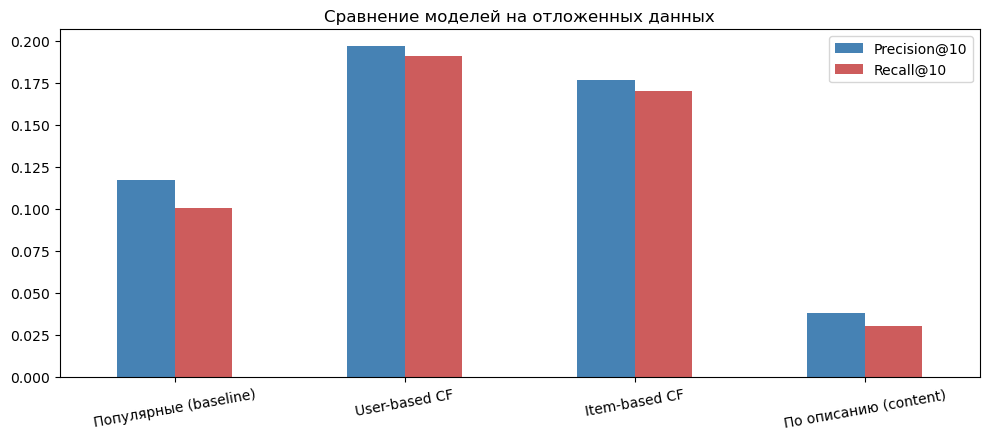

In [42]:
ax = results.plot.bar(figsize=(10, 4.5), rot=10, color=["steelblue", "indianred"])
ax.set_title("Сравнение моделей на отложенных данных")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 13. Выводы

- **Популярность** - быстрая, не требует истории пользователя, но не персонализирована; служит базовым уровнем и решением для новых пользователей.
- **Коллаборативаня фильтрация по пользователям** - учитывает вкус конкретного человека; чувствительна к разреженности, требует хотя бы нескольких оценок.
- **Коллаборативная фильтрация по фильмам** - стабильнее, «похожие фильмы» можно считать заранее; хорошо подходит для блока «Похожие фильмы».
- **По контенту (описание + жанры)** - не зависит от оценок, решает холодный старт для новых фильмов, находит фильмы с похожим сюжетом, а не только с теми же жанрами.
- **Персональные по описанию** - профиль вкуса строится из описаний понравившихся пользователю фильмов, каждая рекомендация объясняется ("похоже на …"). Метрики ниже, чем у коллаборативной фильтрации: описание не знает, какие фильмы в целом любят зрители. Зато метод объяснимый и работает для фильмов без оценок.
- **Гибрид** сочетает коллаборативную фильтрацию и описание и работает для нового пользователя после нескольких оценок.